# Photo Retouch — Refinement Experiments

Advanced Mathematics for Deep Learning final project.

This notebook continues `photo_retouch_training.ipynb`. That notebook keeps
every earlier experiment with its outputs and is no longer extended. Its
reusable code now lives in the `photo_retouch` package (`src/photo_retouch/`),
so this notebook imports functions instead of redefining them.

Nothing here retrains earlier models. They are loaded from `models/`, and every
evaluation uses the frozen validation snapshot in `records/`. The first
sections restore that state and check it against the saved records.

## Setup

Install the package in the notebook's environment once (see ENVIRONMENT.md):

```bash
python -m pip install --no-build-isolation --no-deps -e .
```

The install is editable: after changing a file in `src/photo_retouch/`, restart
the kernel to use the new code. No reinstall is needed.

| Module | Contents |
| --- | --- |
| `data` | Image loading, the validation set, mixed masks, training batches |
| `models` | Coarse U-Net loading, gated-conv refiner, patch discriminator, refine functions |
| `features` | Frozen VGG16 and InceptionV3 extractors |
| `losses` | Masked L1, perceptual, style, and hinge losses |
| `training` | Loss-weight calibration, the adversarial refiner update, resumable training runs |
| `metrics` | Masked MAE, frequency errors, perceptual distance, KID, detail energy, grid test, paired comparisons |
| `plotting` | Side-by-side visual comparisons and enlarged crops |

In [1]:
import pandas as pd
import tensorflow as tf

from photo_retouch.data import load_validation_set
from photo_retouch.device import configure_device
from photo_retouch.metrics import Evaluator
from photo_retouch.models import (
    COARSE_MODEL_FILE,
    SAVED_REFINERS,
    load_saved_model,
    predict_coarse,
    refine_images,
)
from photo_retouch.plotting import show_comparison
from photo_retouch.training import saved_loss_weights

TRAINING_DEVICE = configure_device()
print(f"TensorFlow: {tf.__version__}")
print(f"Preferred device: {TRAINING_DEVICE}")

TensorFlow: 2.18.1
Preferred device: /GPU:0


## Load the Frozen Validation Setup

Read the 400 validation images and their fixed mixed masks from the experiment
snapshot. Preprocessing matches training: decode, scale to [0, 1], and resize
to 128 × 128. The fixed visual examples are the highest-coverage image of each
category.

In [2]:
validation = load_validation_set()
examples = validation.example_indices()

print(f"Snapshot: {validation.record_dir.name}")
print(f"Validation images: {len(validation)}")
print(f"Mean hole coverage: {validation.masks.mean():.1%}")

Snapshot: 20261117T213223_080287Z
Validation images: 400
Mean hole coverage: 13.7%


## Reconstruct the Validation Set with the Saved Models

The frozen coarse U-Net fills each hole, and each refiner refines that coarse
result. `SAVED_REFINERS` pairs every saved refiner with the function it was
trained with. The low-chroma refiners must be applied with
`refine_low_chroma`; with `refine`, their colours are wrong.

In [3]:
COARSE_NAME = "Deep U-Net (MAE reference)"

coarse_model = load_saved_model(COARSE_MODEL_FILE)
reconstructions = {COARSE_NAME: predict_coarse(coarse_model, validation)}

for name, (filename, refine_fn) in SAVED_REFINERS.items():
    refiner = load_saved_model(filename)
    reconstructions[name] = refine_images(
        refiner, reconstructions[COARSE_NAME], validation.masks, refine_fn
    )
    print(f"{name:<22} {filename:<28} {refine_fn.__name__}")

L1 refiner             refiner_l1_control.keras     refine


Texture refiner        refiner_texture.keras        refine


Low-chroma refiner     refiner_low_chroma.keras     refine_low_chroma


Low-chroma, no style   refiner_no_style.keras       refine_low_chroma


## Check the Restored State Against the Saved Records

Recompute every metric with the package and compare it with the tables saved
by the earlier notebook:

- the metric summaries of the refinement experiment and its follow-up;
- the paired comparisons of the follow-up variants;
- the colour-fringing (detail energy) ratios;
- the grid-periodicity test.

If the values match, the data, models, and metric code were carried over
unchanged. Any difference stops the notebook here. The experiments below
save their tables with `save_or_check`: the first execution writes the
record, and every later one must reproduce it.

In [4]:
evaluator = Evaluator(validation)
evaluations = {
    name: evaluator.evaluate(results) for name, results in reconstructions.items()
}

PAIRS = [
    ("Low-chroma refiner", COARSE_NAME),
    ("Low-chroma refiner", "Texture refiner"),
    ("Low-chroma, no style", COARSE_NAME),
    ("Low-chroma, no style", "Texture refiner"),
    ("Low-chroma, no style", "Low-chroma refiner"),
]

recomputed = {
    "metric_summary": pd.DataFrame({
        name: evaluation.summary() for name, evaluation in evaluations.items()
    }).T,
    "paired_comparisons": pd.DataFrame([
        {"method": method, "baseline": baseline,
         **evaluator.paired(evaluations[method], evaluations[baseline])}
        for method, baseline in PAIRS
    ]).set_index(["method", "baseline"]),
    "detail_energy": pd.DataFrame({
        name: evaluator.detail_summary(results)
        for name, results in reconstructions.items()
    }).T,
    "grid_periodicity": pd.DataFrame([
        {"method": name, **row}
        for name, images in {
            "True image": validation.originals, **reconstructions
        }.items()
        for row in evaluator.grid_periodicity(images)
    ]).set_index(["method", "direction"]),
}

In [5]:
REFINE_DIR = validation.record_dir / "refinement"
FOLLOWUP_DIR = validation.record_dir / "refinement_followup"
TOLERANCE = 1e-6

saved = {
    "metric_summary": pd.concat([
        pd.read_csv(REFINE_DIR / "metric_summary.csv", index_col="method"),
        pd.read_csv(FOLLOWUP_DIR / "metric_summary.csv", index_col="method"),
    ]),
    "paired_comparisons": pd.read_csv(
        FOLLOWUP_DIR / "paired_comparisons.csv", index_col=["method", "baseline"]
    ),
    "detail_energy": pd.read_csv(
        FOLLOWUP_DIR / "detail_energy.csv", index_col="method"
    ),
    "grid_periodicity": pd.read_csv(
        FOLLOWUP_DIR / "grid_periodicity_variants.csv",
        index_col=["method", "direction"],
    ),
}


def compare_with_record(new_table, saved_table):
    # Methods saved in both experiments appear twice; keep the latest row.
    saved_table = saved_table[~saved_table.index.duplicated(keep="last")]
    shared = new_table.index.intersection(saved_table.index)
    new = new_table.loc[shared, saved_table.columns]
    old = saved_table.loc[shared]
    numeric = old.select_dtypes("number").columns
    text = old.columns.difference(numeric)
    return {
        "rows compared": len(shared),
        "max numeric difference": (
            new[numeric].astype(float) - old[numeric]
        ).abs().max().max(),
        "text cells differing": int((new[text].astype(str) != old[text]).sum().sum()),
    }


def save_or_check(table, path):
    # Write a new record; if it exists, the recomputed table must match it.
    if not path.exists():
        table.to_csv(path)
        return
    saved_table = pd.read_csv(path, index_col=list(range(table.index.nlevels)))
    check = compare_with_record(table, saved_table)
    assert check["rows compared"] == len(table), (path.name, check)
    assert check["max numeric difference"] < TOLERANCE, (path.name, check)
    assert check["text cells differing"] == 0, (path.name, check)


state_check = pd.DataFrame({
    table: compare_with_record(recomputed[table], saved[table])
    for table in saved
}).T.astype({"rows compared": int, "text cells differing": int})
display(state_check)

assert (state_check["max numeric difference"] < TOLERANCE).all()
assert (state_check["text cells differing"] == 0).all()
print("The restored state reproduces the saved records.")

,rows compared,max numeric difference,text cells differing
metric_summary,5,2.761307e-08,0
paired_comparisons,5,4.880524e-09,0
detail_energy,4,4.330139e-08,0
grid_periodicity,8,0.000000e+00,0


The restored state reproduces the saved records.


## Results So Far

Pixel error, perceptual distance, and KID (lower is better for all three),
with the fine-detail energy in luminance and chroma relative to the true
images (1 matches the truth). The paired comparisons give image-by-image
differences with 95% bootstrap intervals; negative values favour the method.

In [6]:
overview = recomputed["metric_summary"][
    ["masked_mae", "feature_distance", "kid_x1000"]
].join(recomputed["detail_energy"][["luma_detail_ratio", "chroma_detail_ratio"]])

with pd.option_context("display.width", 200, "display.max_columns", 20):
    display(overview.round(4))
    display(recomputed["paired_comparisons"].round(4))

,masked_mae,feature_distance,kid_x1000,luma_detail_ratio,chroma_detail_ratio
Deep U-Net (MAE reference),0.0932,0.8803,4.7893,0.0292,0.2835
L1 refiner,0.0930,0.8758,4.6346,0.0279,0.2820
Texture refiner,0.1044,0.7057,-0.1895,0.6803,3.8364
Low-chroma refiner,0.1059,0.7083,0.0677,0.8070,1.0888
"Low-chroma, no style",0.0992,0.7229,0.4159,0.4707,0.7489


masked_mae Δ   masked_mae 95% CI masked_mae images better  feature_distance Δ feature_distance 95% CI feature_distance images better  KID×1000 Δ  \
method               baseline                                                                                                                                                                       
Low-chroma refiner   Deep U-Net (MAE reference)        0.0127  [+0.0117, +0.0136]                       6%             -0.1720      [-0.1875, -0.1572]                            93%     -4.7216   
                     Texture refiner                   0.0016  [+0.0012, +0.0020]                      36%              0.0027      [-0.0025, +0.0081]                            49%      0.2571   
Low-chroma, no style Deep U-Net (MAE reference)        0.0059  [+0.0053, +0.0065]                      11%             -0.1574      [-0.1704, -0.1450]                            96%     -4.3734   
                     Texture refiner                  -0.0052  [-0.0057, -0.0048]                      91%              0.0173      [+0.0101, +0.0243]                            42%      0.6053   
                     Low-chroma refiner               -0.0068  [-0.0073, -0.0063]                      95%              0.0146      [+0.0073, +0.0215]                            47%      0.3482   

                                                KID subsets lower  
method               baseline                                      
Low-chroma refiner   Deep U-Net (MAE reference)              100%  
                     Texture refiner                          16%  
Low-chroma, no style Deep U-Net (MAE reference)              100%  
                     Texture refiner                           9%  
                     Low-chroma refiner                       20%

## Visual Check

The coarse fill, the texture refiner, and both follow-up variants on the
fixed examples.

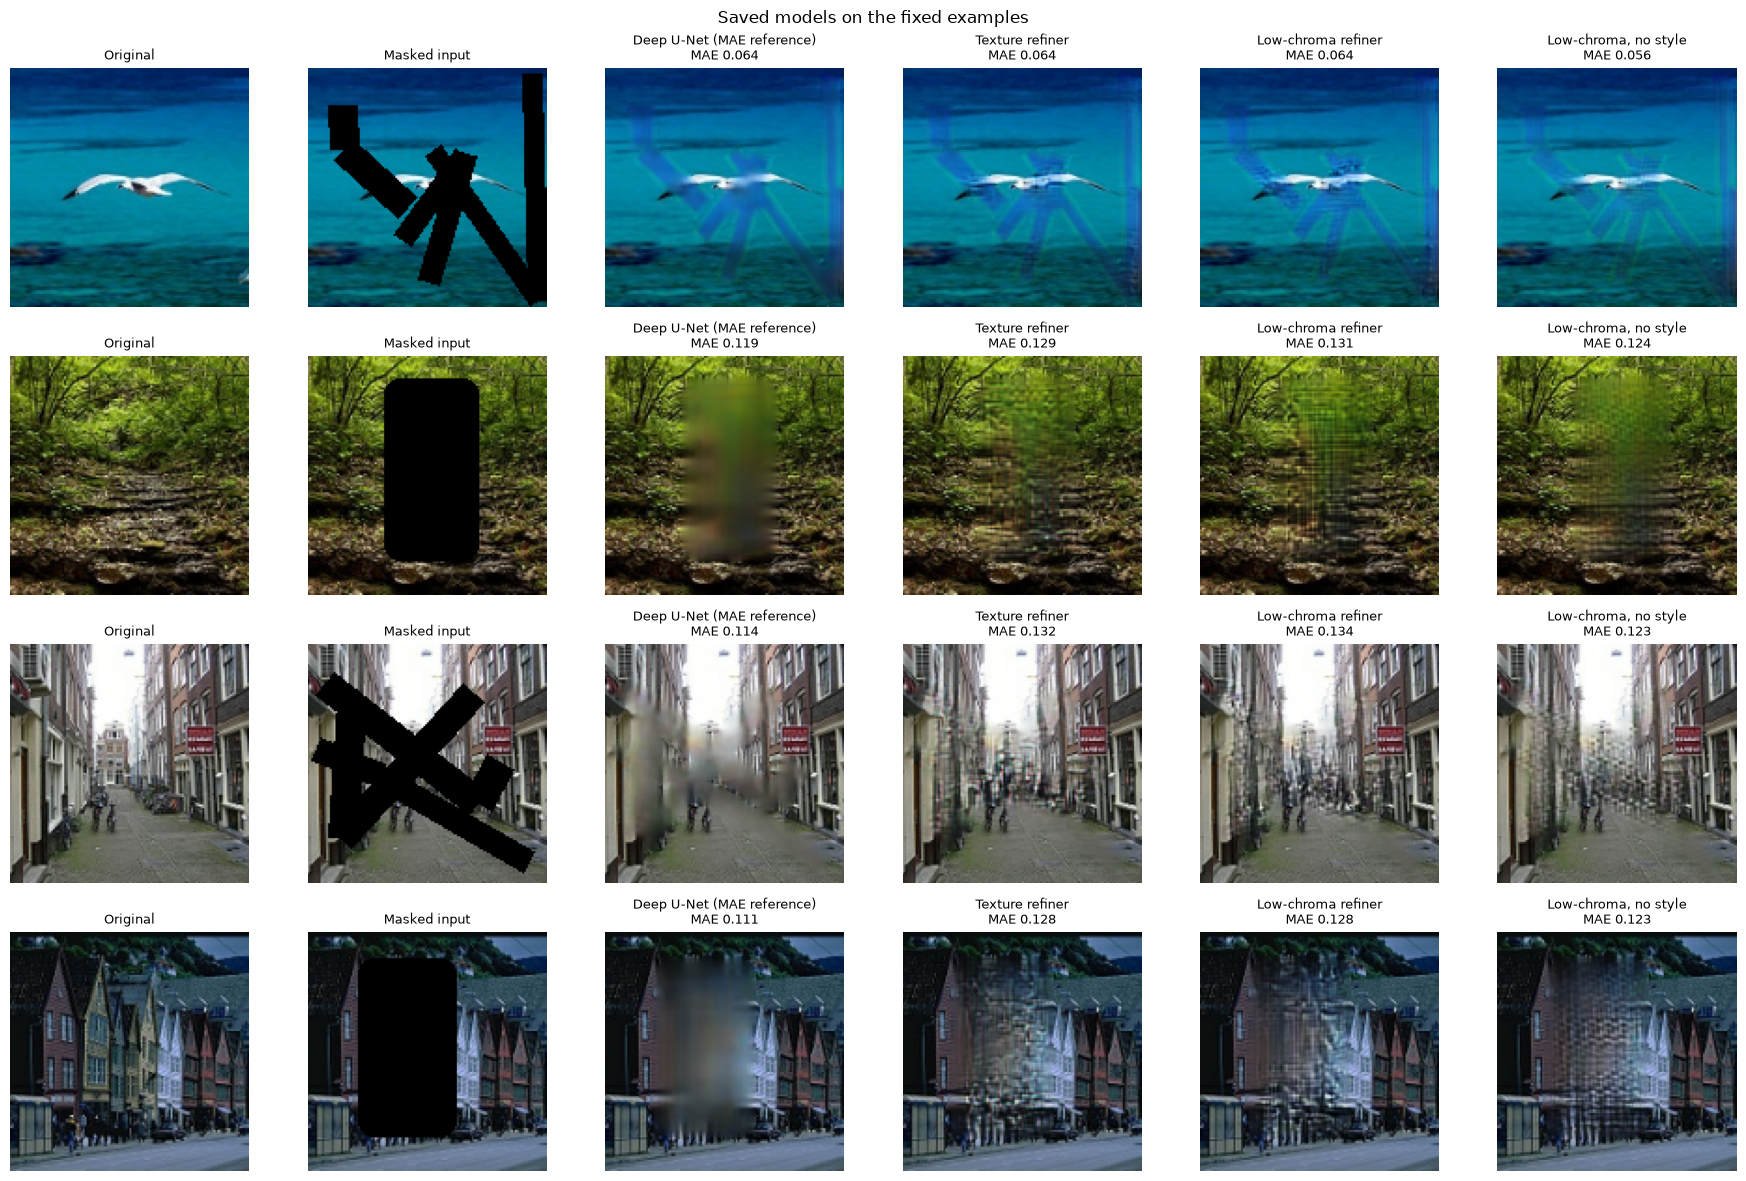

In [7]:
show_comparison(
    validation,
    {
        name: reconstructions[name]
        for name in [
            COARSE_NAME, "Texture refiner",
            "Low-chroma refiner", "Low-chroma, no style",
        ]
    },
    examples,
    "Saved models on the fixed examples",
)

## Training Settings Carried Over

The refiners were trained with loss weights calibrated so that the perceptual
and style gradients initially match the masked-L1 gradient, and with an
adaptive adversarial weight at half the reconstruction gradient. The values
are stored in the refinement checkpoint. `photo_retouch.training` also
provides the same training batches (`TrainingBatches`), the calibration
(`calibrate_loss_weights`), the adversarial update (`new_arm`,
`make_train_step`), and a checkpointed, resumable training loop
(`CheckpointedRun`) for new variants.

In [8]:
PERCEPTUAL_WEIGHT, STYLE_WEIGHT, ADV_RATIO = saved_loss_weights()

print(f"Perceptual weight: {PERCEPTUAL_WEIGHT:.4g}")
print(f"Style weight: {STYLE_WEIGHT:.4g}")
print(f"Adversarial ratio: {ADV_RATIO:g}")

Perceptual weight: 0.0002139
Style weight: 8.88e-05
Adversarial ratio: 0.5


## Starting Point

**Best candidate: the low-chroma refiner.** Compared with the coarse U-Net, it
lowers perceptual distance from 0.880 to 0.708 and KID × 1000 from 4.79 to
0.07, at a cost of 0.013 in masked MAE. It removes the texture refiner's
colour fringing (chroma detail 1.09 times the truth instead of 3.84) with no
measurable loss in perceptual distance.

**Open problem: a blocky luminance mosaic on facades.** Removing the style
loss made it worse, as Liu et al. (2018) report for perceptual losses without
a style term. Two causes remain untested:

1. **Style weight too small.** Liu et al. observe "fish scale" artifacts when
   the style weight is small. Ours was set by a gradient-norm heuristic, and
   its relative weight is much lower than theirs.
2. **Nearest-neighbour upsampling.** The low-chroma refiner has a 4-px grid
   component about twice that of the true images. That period matches the
   decoder's two ×2 nearest-neighbour upsampling layers.

**Human judgement is still missing.** The blind-review pages in `records/`
were generated before the refiners existed. A new panel that includes the
low-chroma refiner is needed to check whether the measured gain outweighs
the visible artifacts.

Each refiner variant is a single training run, so small differences may
reflect initialization rather than the change being tested.

## Experiment: Style Weight

**Question.** Is the blocky luminance mosaic of the low-chroma refiner caused
by a style weight that is too small?

Liu et al. (2018) report "fish scale" artifacts when the style weight is
small. Ours was set by equalizing gradient norms at initialization, not
tuned. Their weights (hole L1 6, perceptual 0.05, style 120) do not transfer
directly: the style term grows with the square of the feature scale and the
perceptual term only linearly, and our VGG16 receives 0–255 inputs. The
experiment therefore sweeps the weight over two orders of magnitude instead
of copying one value.

**Design.** Two new low-chroma refiners, with the calibrated style weight
multiplied by 10 and by 100. Everything else matches the earlier follow-up:
initialization (seed 2042), training images and masks, 3,000 updates,
perceptual weight, and adversarial ratio. With the existing variants (no
style, ×0; low-chroma refiner, ×1), this gives four points along one axis.
The adversarial weight is set relative to the reconstruction gradient, so it
rises in proportion; what changes is the balance between the style term and
L1 plus perceptual.

**Predictions.** If the weight is the cause, the grid-aligned components at
2 and 4 px should keep falling from ×0 to ×100 toward the level of the true
images, and facades should look less blocky. If they do not fall, the weight
is ruled out and the nearest-neighbour upsampling becomes the next test.

**Criterion for a new best candidate** (fixed before training). Compared with
the low-chroma refiner, a variant must:

1. lower the 2- and 4-px grid components in both directions, and
2. not worsen perceptual distance: the paired 95% interval must not lie
   entirely above zero.

KID differences smaller than one subset standard deviation (about 2 on the
×1000 scale) count as ties. Masked MAE is expected to rise as the style term
outweighs L1; it is reported as the cost, not used as a criterion.

In [9]:
from tensorflow import keras

from photo_retouch.data import TrainingBatches
from photo_retouch.features import LOSS_LAYERS, vgg16_features
from photo_retouch.models import (
    CHROMA_SIGMA,
    build_patch_discriminator,
    build_refiner,
    make_coarse_composite,
    refine_low_chroma,
)
from photo_retouch.paths import MODEL_DIR
from photo_retouch.training import CheckpointedRun, make_train_step, new_arm

INIT_SEED = 2042
STYLE_STEPS = 3000
STYLE_ARMS = {
    # name: (log key, multiple of the calibrated style weight)
    "Low-chroma, style ×10": ("style_x10", 10),
    "Low-chroma, style ×100": ("style_x100", 100),
}
STYLE_RECORD_DIR = validation.record_dir / "refinement_style_weight"
STYLE_CHECKPOINT_DIR = MODEL_DIR / "refinement_style_weight"
STYLE_MODEL_DIR = MODEL_DIR

batches = TrainingBatches()
coarse_composite = make_coarse_composite(coarse_model)
loss_features = vgg16_features(LOSS_LAYERS)

# The shared initialization of the earlier follow-up variants.
keras.utils.set_random_seed(INIT_SEED)
initial_refiner = build_refiner("followup_initial_refiner")
initial_discriminator = build_patch_discriminator()

style_arms = {
    name: new_arm(
        key, refine_low_chroma, multiple * STYLE_WEIGHT,
        initial_refiner, initial_discriminator,
    )
    for name, (key, multiple) in STYLE_ARMS.items()
}
for name, arm in style_arms.items():
    print(f"{name:<24} style weight {arm.style_weight:.3g}")

Low-chroma, style ×10    style weight 0.000888
Low-chroma, style ×100   style weight 0.00888


### Check the Shared Starting Point

The comparison with the ×0 and ×1 variants is controlled only if the new
arms start from the same weights and see the same batches. A ×1 arm built
from this initialization must reproduce the first two logged updates of the
saved low-chroma run.

In [10]:
followup_log = pd.read_csv(FOLLOWUP_DIR / "training_log.csv", index_col="step")

check_arm = new_arm(
    "low_chroma", refine_low_chroma, STYLE_WEIGHT,
    initial_refiner, initial_discriminator,
)
check_step = make_train_step(
    [check_arm], coarse_composite, loss_features, PERCEPTUAL_WEIGHT, ADV_RATIO
)
start_check = pd.DataFrame([
    {"step": step + 1, "value": name,
     "relative difference": abs(float(value) - followup_log.loc[step + 1, name])
     / abs(followup_log.loc[step + 1, name])}
    for step in range(2)
    for name, value in check_step(*batches(step)).items()
])
largest = start_check["relative difference"].max()
print(f"Largest relative difference over {len(start_check)} logged values: {largest:.1e}")
assert largest < 1e-5
del check_arm, check_step

Largest relative difference over 10 logged values: 0.0e+00


### Train

Both arms are updated on the same batch at every step. The run is
checkpointed every 250 updates; re-running this cell resumes from the last
checkpoint, or does nothing if all 3,000 updates are done. Logged values:
masked L1, perceptual and style (Gram) distances before weighting, the
discriminator's hinge loss, and the adaptive adversarial weight.

In [11]:
arms = list(style_arms.values())
style_run = CheckpointedRun(
    arms,
    make_train_step(arms, coarse_composite, loss_features, PERCEPTUAL_WEIGHT, ADV_RATIO),
    batches,
    STYLE_CHECKPOINT_DIR,
    STYLE_RECORD_DIR / "training_log.csv",
    settings={
        "perceptual_weight": PERCEPTUAL_WEIGHT,
        "adv_ratio": ADV_RATIO,
        "chroma_sigma": CHROMA_SIGMA,
        "init_seed": INIT_SEED,
        **{f"{arm.key}_style_weight": arm.style_weight for arm in arms},
    },
)
style_run.run(STYLE_STEPS)

for arm in arms:
    arm.refiner.save(STYLE_MODEL_DIR / f"refiner_{arm.key}.keras")
print(f"Completed updates per variant: {style_run.completed}")

Restored 3000 completed updates from the checkpoint.
Steps 1–250 (logged)
  style_x10        L1: 0.1043 | Perc: 287.2 | Style: 689.6 | D: 1.917 | Adv weight: 1.19
  style_x100       L1: 0.1158 | Perc: 295.8 | Style: 704.4 | D: 1.911 | Adv weight: 12.2
Steps 251–500 (logged)
  style_x10        L1: 0.1107 | Perc: 291.5 | Style: 548.8 | D: 1.881 | Adv weight: 0.305
  style_x100       L1: 0.1204 | Perc: 304.8 | Style: 577.9 | D: 1.849 | Adv weight: 2.98
Steps 501–750 (logged)
  style_x10        L1: 0.1103 | Perc: 291.6 | Style: 502.3 | D: 1.798 | Adv weight: 0.279
  style_x100       L1: 0.1165 | Perc: 301.8 | Style: 520.3 | D: 1.802 | Adv weight: 2.11
Steps 751–1000 (logged)
  style_x10        L1: 0.1123 | Perc: 292.2 | Style: 472.5 | D: 1.778 | Adv weight: 0.217
  style_x100       L1: 0.1186 | Perc: 300.9 | Style: 487.3 | D: 1.866 | Adv weight: 2.31
Steps 1001–1250 (logged)
  style_x10        L1: 0.1169 | Perc: 294.5 | Style: 446.3 | D: 1.937 | Adv weight: 0.343
  style_x100       L1: 0.1

### Evaluate

The four low-chroma variants ordered by style weight. Grid components are
the strength of luminance jumps that repeat every 2 or 4 px, aligned with
the image grid (the true images' level is the reference). Detail ratios are
fine-detail energy relative to the truth (1 matches it). The Gram distance
is the training style loss, averaged over the last 250 updates.

In [12]:
STYLE_RECORD_DIR.mkdir(parents=True, exist_ok=True)

for name, arm in style_arms.items():
    reconstructions[name] = refine_images(
        arm.refiner, reconstructions[COARSE_NAME], validation.masks, refine_low_chroma
    )
    evaluations[name] = evaluator.evaluate(reconstructions[name])

STYLE_SERIES = {
    # multiple of the style weight: (method, log key)
    0: ("Low-chroma, no style", "no_style"),
    1: ("Low-chroma refiner", "low_chroma"),
    10: ("Low-chroma, style ×10", "style_x10"),
    100: ("Low-chroma, style ×100", "style_x100"),
}
style_logs = followup_log.join(style_run.log_frame().set_index("step"))
last_window = style_logs[style_logs.index > STYLE_STEPS - 250]


def grid_by_period(images):
    table = pd.DataFrame(evaluator.grid_periodicity(images)).set_index("direction")
    return {
        f"grid {period} px ({direction[0]})": table.loc[direction, f"period {period} px"]
        for period in [2, 4] for direction in ["horizontal", "vertical"]
    }


style_rows = []
for multiple, (name, key) in STYLE_SERIES.items():
    summary = evaluations[name].summary()
    detail = evaluator.detail_summary(reconstructions[name])
    style_rows.append({
        "style multiple": multiple,
        "method": name,
        "masked_mae": summary["masked_mae"],
        "feature_distance": summary["feature_distance"],
        "kid_x1000": summary["kid_x1000"],
        "luma_detail_ratio": detail["luma_detail_ratio"],
        "chroma_detail_ratio": detail["chroma_detail_ratio"],
        **grid_by_period(reconstructions[name]),
        "train_gram_distance": last_window[f"{key}_style"].mean(),
        "train_l1": last_window[f"{key}_l1"].mean(),
    })
style_table = pd.DataFrame(style_rows).set_index("style multiple")
true_grid = pd.Series(grid_by_period(validation.originals), name="True image")

STYLE_PAIRS = [
    (name, baseline)
    for name in STYLE_ARMS
    for baseline in [COARSE_NAME, "Low-chroma refiner"]
] + [("Low-chroma, style ×100", "Low-chroma, style ×10")]
style_paired = pd.DataFrame([
    {"method": method, "baseline": baseline,
     **evaluator.paired(evaluations[method], evaluations[baseline])}
    for method, baseline in STYLE_PAIRS
]).set_index(["method", "baseline"])

save_or_check(style_table, STYLE_RECORD_DIR / "style_weight_summary.csv")
save_or_check(style_paired, STYLE_RECORD_DIR / "paired_comparisons.csv")
save_or_check(
    pd.DataFrame({
        name: evaluations[name].summary() for name in STYLE_ARMS
    }).T.rename_axis("method"),
    STYLE_RECORD_DIR / "metric_summary.csv",
)
save_or_check(pd.DataFrame([
    {"method": name, **row}
    for name, images in {
        "True image": validation.originals,
        **{name: reconstructions[name] for name in STYLE_ARMS},
    }.items()
    for row in evaluator.grid_periodicity(images)
]).set_index(["method", "direction"]), STYLE_RECORD_DIR / "grid_periodicity.csv")

with pd.option_context("display.width", 250, "display.max_columns", 20):
    display(style_table.round(4))
    display(true_grid.round(4).to_frame().T)
    display(style_paired.round(4))

,method,masked_mae,feature_distance,kid_x1000,luma_detail_ratio,chroma_detail_ratio,grid 2 px (h),grid 2 px (v),grid 4 px (h),grid 4 px (v),train_gram_distance,train_l1
style multiple,,,,,,,,,,,,
0,"Low-chroma, no style",0.0992,0.7229,0.4159,0.4707,0.7489,0.1133,0.0481,0.0248,0.0226,512.2144,0.1000
1,Low-chroma refiner,0.1059,0.7083,0.0677,0.8070,1.0888,0.0277,0.0324,0.0107,0.0099,406.5584,0.1052
10,"Low-chroma, style ×10",0.1145,0.7580,0.7645,1.0230,1.1625,0.0045,0.0162,0.0108,0.0058,391.2730,0.1136
100,"Low-chroma, style ×100",0.1164,0.8023,1.7712,1.0406,1.1242,0.0072,0.0272,0.0136,0.0039,405.5726,0.1165


,grid 2 px (h),grid 2 px (v),grid 4 px (h),grid 4 px (v)
True image,0.0004,0.0003,0.0046,0.0048


masked_mae Δ   masked_mae 95% CI masked_mae images better  feature_distance Δ feature_distance 95% CI feature_distance images better  KID×1000 Δ KID subsets lower
method                 baseline                                                                                                                                                                                      
Low-chroma, style ×10  Deep U-Net (MAE reference)        0.0212  [+0.0200, +0.0225]                       1%             -0.1222      [-0.1370, -0.1075]                            84%     -4.0248              100%
                       Low-chroma refiner                0.0085  [+0.0079, +0.0092]                       6%              0.0497      [+0.0431, +0.0566]                            22%      0.6968                2%
Low-chroma, style ×100 Deep U-Net (MAE reference)        0.0231  [+0.0220, +0.0243]                       1%             -0.0780      [-0.0936, -0.0625]                            73%     -3.0180              100%
                       Low-chroma refiner                0.0104  [+0.0097, +0.0112]                       5%              0.0939      [+0.0842, +0.1044]                            12%      1.7035                0%
                       Low-chroma, style ×10             0.0019  [+0.0013, +0.0026]                      38%              0.0442      [+0.0366, +0.0524]                            28%      1.0068                3%

### Visual Check

All four style weights on the fixed examples, then enlarged crops of the
filled region on the two facade examples, displayed pixel for pixel so the
mosaic is not smoothed away.

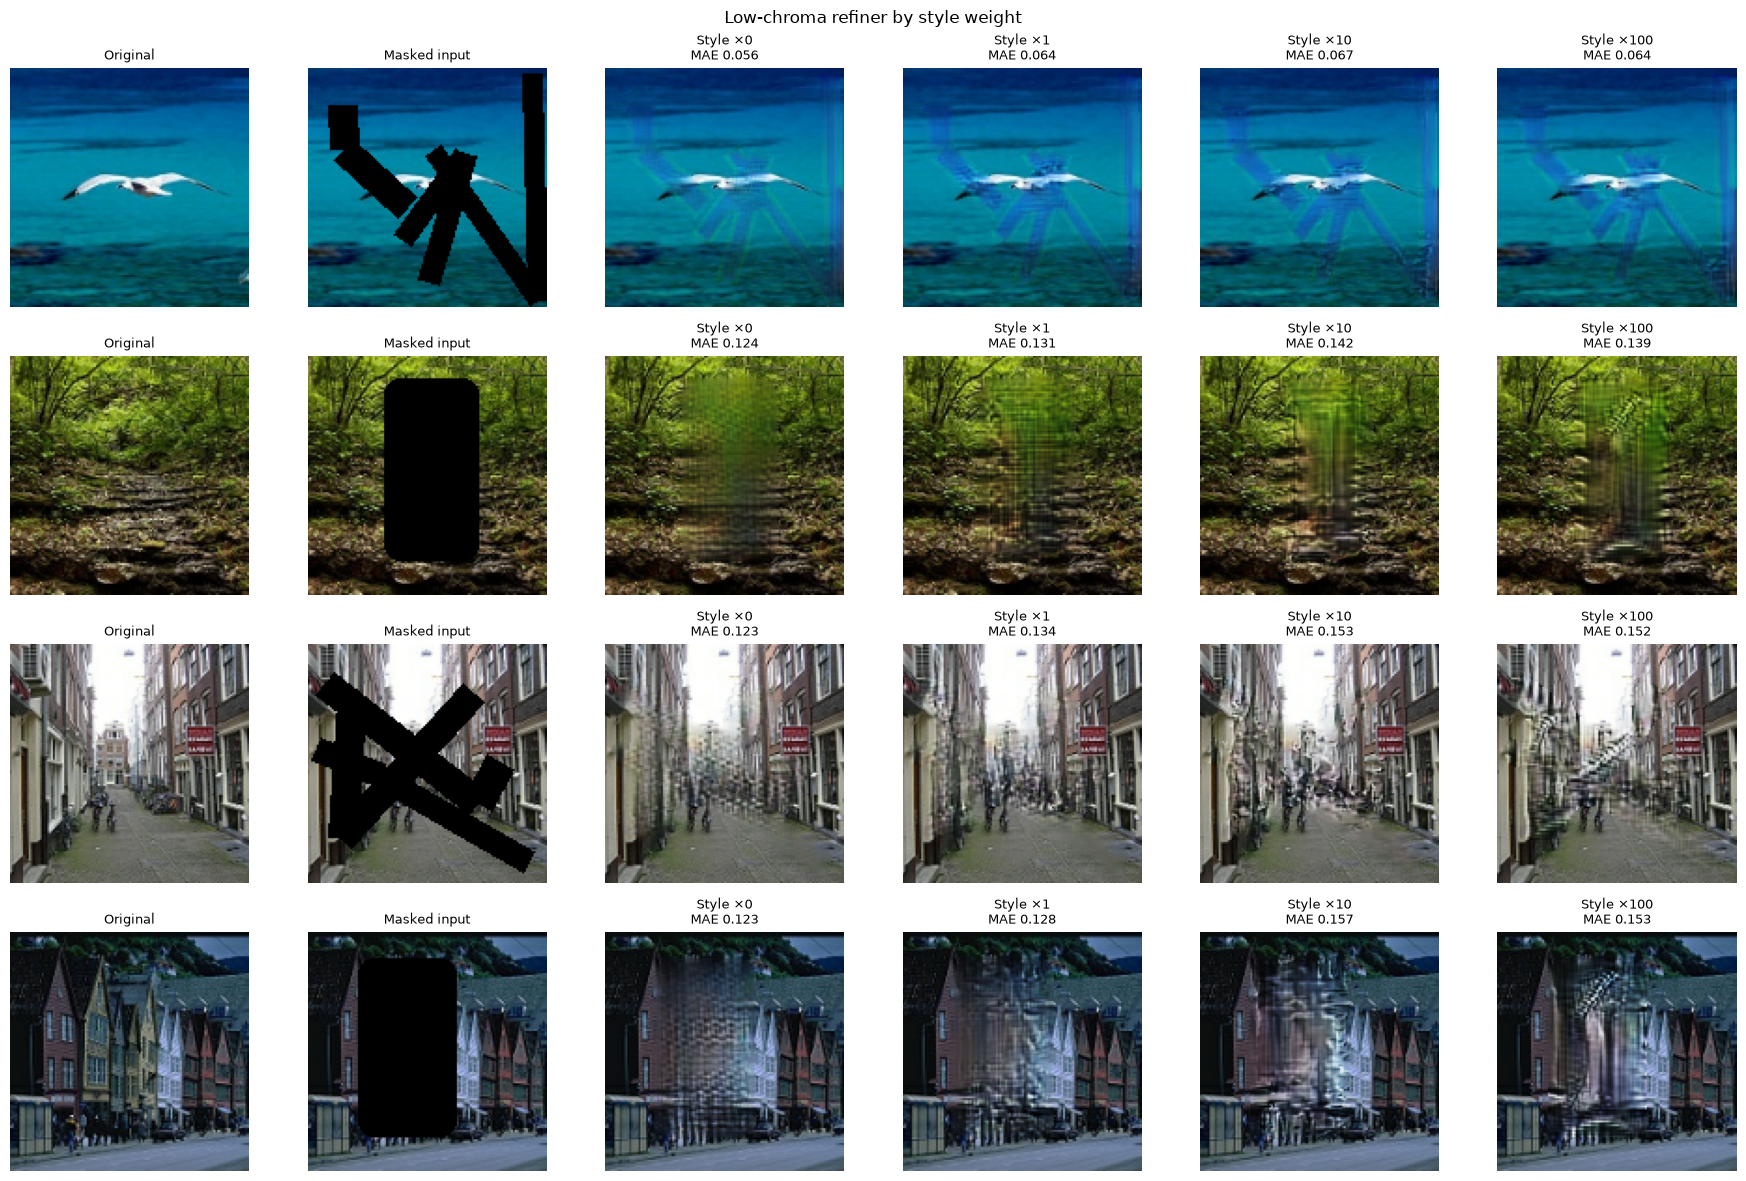

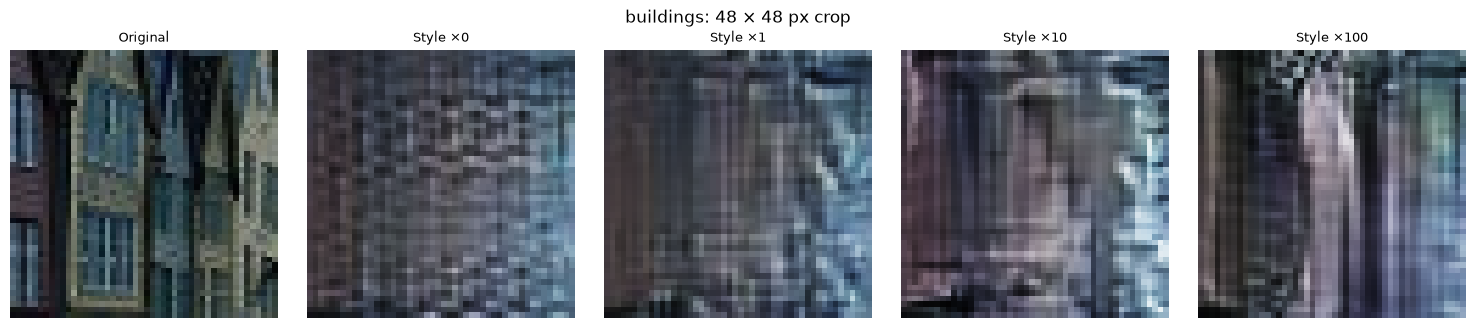

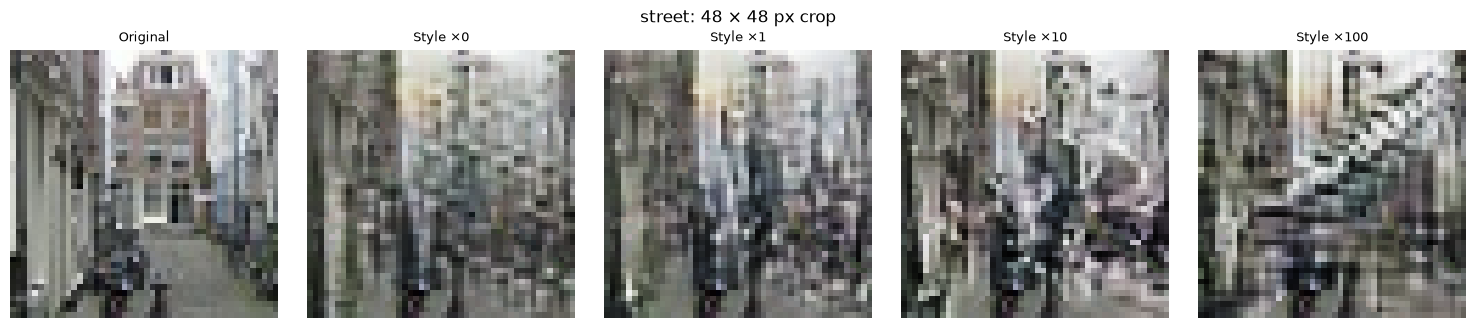

In [13]:
from photo_retouch.plotting import show_zoom

style_results = {
    f"Style ×{multiple}": reconstructions[name]
    for multiple, (name, _) in STYLE_SERIES.items()
}
show_comparison(validation, style_results, examples, "Low-chroma refiner by style weight")

for category, index in zip(
    ["buildings", "street"], validation.example_indices(["buildings", "street"])
):
    show_zoom(validation, style_results, index, title=f"{category}: 48 × 48 px crop")

### Style-Weight Results

**The criterion is not met. The low-chroma refiner (×1) remains the best
candidate.**

- **Grid.** Neither variant lowers all four grid components. At ×10 the
  horizontal 2-px component falls from 0.028 to 0.004 (true images: 0.0004),
  the vertical one halves (0.032 to 0.016), and the vertical 4-px component
  nears the true level (0.006 vs 0.005). The horizontal 4-px component does
  not change (0.0108 vs 0.0107; true images: 0.0046). ×100 is worse than
  ×10 on three of the four components.
- **Perceptual distance** worsens as the weight grows: +0.050 at ×10
  (95% CI [+0.043, +0.057]) and +0.094 at ×100 ([+0.084, +0.104]), compared
  with ×1. KID × 1000 rises by 0.70 and 1.70. Both rises are below one subset
  standard deviation (about 2), so they count as ties, but the new variants
  are lower in only 2% and 0% of the subsets. Masked MAE rises by 0.0085
  and 0.0104.
- **Visually,** the stronger weight replaces the mosaic with other regular
  artifacts rather than natural texture: vertical streaks and smeared
  facades at ×10, diagonal checkered bands at ×100 (the building and street
  crops, and the top of the forest fill). The amount of fine luminance
  detail now matches the truth (ratio 1.02 and 1.04, against 0.81 at ×1).
  The remaining problem is how that detail is arranged, not how much of it
  there is.

**The style loss stops falling.** Over the last 250 updates, the Gram
distance the refiner reaches is 512 without style, 407 at ×1, 391 at ×10,
and 406 at ×100. Raising the weight a hundredfold does not lower the style
loss. It raises the masked L1 (0.105 to 0.116) and the unweighted perceptual
loss (266 to 291). Within 3,000 updates, this refiner cannot match the true
texture statistics any more closely, however strongly it is pushed to.
Hypothesis 1 (style weight too small) is not supported over this range.

**Next.** The mosaic is not a weighting problem. Its 2- and 4-px periods
match the refiner's two nearest-neighbour upsampling stages (hypothesis 2).
They also match two parts of the losses: the first two pooling stages of
the VGG16 layers behind the perceptual and style terms, and the stride-2
convolutions of the discriminator, which the adversarial gradient passes
through. Changing only the upsampling would test hypothesis 2, but
a null result would not separate the other two sources.

**Limitations.** Each variant is a single training run. The perceptual
distance shares VGG16 with the training losses, although here it penalizes
the variants trained with more style.

## Experiment: Source of the Grid Artifact

**Question.** Where does the grid in the refiners' texture come from?

The style-weight experiment ruled out the weight. Three parts of the
training setup share the 2- and 4-px periods of the grid:

- **Refiner upsampling.** The decoder doubles the resolution twice with
  nearest-neighbour upsampling, which copies each value into 2 × 2 and then
  4 × 4 blocks before the next convolution.
- **VGG16 pooling.** The perceptual and style losses read `block1_pool` to
  `block3_pool`, which follow 2 × 2 max pooling at strides of 2, 4, and 8 px.
- **Discriminator strides.** The patch discriminator has four stride-2
  convolutions, and the adversarial gradient passes back through them.

A loss network can teach the refiner a pattern at fixed image positions
only if it always sees the image at the same positions. Rolling the images
it sees by a random offset at each update removes that alignment without
changing what it measures.

**Design.** A 2 × 2 comparison, all at the calibrated style weight (×1) and
with the shared initialization, batches, and 3,000 updates of the earlier
variants:

| | Loss networks at fixed positions | Loss networks at random offsets |
| --- | --- | --- |
| Nearest-neighbour upsampling | Low-chroma refiner (already trained) | Shifted losses |
| Bilinear upsampling | Bilinear | Bilinear + shifted |

For the shifted arms, the truth, the result, and the mask are rolled by the
same offset before VGG16 and the discriminator see them. The offset is drawn
from 0–15 px per axis at every update, with wrap-around at the borders.
Masked L1 is unchanged.

**Predictions.** The grid test measures jumps at the same positions (modulo
16 px) in every image.

- If the upsampling is the source, both bilinear arms lower the 2- and 4-px
  components and shifting alone does not.
- If the loss networks' alignment is the source, both shifted arms lower
  them and bilinear upsampling alone does not.
- If both contribute, only the combined arm approaches the true images'
  level.

With shifted losses, the refiner could still produce a regular pattern at
positions that vary between images, which the grid test would miss. The
enlarged crops check for that.

**Criterion for a new best candidate** (fixed before training), as in the
style experiment: compared with the low-chroma refiner, lower 2- and 4-px
components in both directions, and a paired 95% interval for perceptual
distance that does not lie entirely above zero.

In [14]:
from photo_retouch.training import SHIFT_SEED

GRID_STEPS = 3000
LOSS_SHIFT = 16
GRID_ARMS = {
    # name: (log key, upsampling, maximum loss-network offset in px)
    "Low-chroma, bilinear": ("bilinear", "bilinear", 0),
    "Low-chroma, shifted losses": ("shifted", "nearest", LOSS_SHIFT),
    "Low-chroma, bilinear + shifted": ("bilinear_shifted", "bilinear", LOSS_SHIFT),
}
GRID_RECORD_DIR = validation.record_dir / "refinement_grid_source"
GRID_CHECKPOINT_DIR = MODEL_DIR / "refinement_grid_source"
GRID_MODEL_DIR = MODEL_DIR

# The same shared initialization as the other follow-up variants.
grid_arms = {
    name: new_arm(
        key, refine_low_chroma, STYLE_WEIGHT, initial_refiner, initial_discriminator,
        upsampling=upsampling, loss_shift=shift,
    )
    for name, (key, upsampling, shift) in GRID_ARMS.items()
}

# Every new refiner starts as the identity: it returns the coarse fill.
probe_images, probe_masks = batches(0)
probe_coarse = coarse_composite(probe_images, probe_masks)
for name, arm in grid_arms.items():
    gap = float(tf.reduce_max(tf.abs(
        refine_low_chroma(arm.refiner, probe_coarse, probe_masks) - probe_coarse
    )))
    assert gap < 2e-3, (name, gap)
    upsampling = arm.refiner.get_layer("up64").interpolation
    print(f"{name:<32} upsampling: {upsampling:<8} loss offset: 0–{max(arm.loss_shift - 1, 0)} px")

Low-chroma, bilinear             upsampling: bilinear loss offset: 0–0 px
Low-chroma, shifted losses       upsampling: nearest  loss offset: 0–15 px


Low-chroma, bilinear + shifted   upsampling: bilinear loss offset: 0–15 px


### Train

The three arms are updated on the same batch at every step, with the same
checkpointing as before.

In [15]:
grid_arm_list = list(grid_arms.values())
grid_run = CheckpointedRun(
    grid_arm_list,
    make_train_step(
        grid_arm_list, coarse_composite, loss_features, PERCEPTUAL_WEIGHT, ADV_RATIO
    ),
    batches,
    GRID_CHECKPOINT_DIR,
    GRID_RECORD_DIR / "training_log.csv",
    settings={
        "perceptual_weight": PERCEPTUAL_WEIGHT,
        "style_weight": STYLE_WEIGHT,
        "adv_ratio": ADV_RATIO,
        "chroma_sigma": CHROMA_SIGMA,
        "init_seed": INIT_SEED,
        "shift_seed": SHIFT_SEED,
        **{f"{key}_loss_shift": shift for key, _, shift in GRID_ARMS.values()},
        **{f"{key}_bilinear": float(upsampling == "bilinear")
           for key, upsampling, _ in GRID_ARMS.values()},
    },
)
grid_run.run(GRID_STEPS)

for arm in grid_arm_list:
    arm.refiner.save(GRID_MODEL_DIR / f"refiner_{arm.key}.keras")
print(f"Completed updates per variant: {grid_run.completed}")

Restored 3000 completed updates from the checkpoint.
Steps 1–250 (logged)
  bilinear         L1: 0.0946 | Perc: 273.8 | Style: 724.9 | D: 1.867 | Adv weight: 0.245
  shifted          L1: 0.0947 | Perc: 273.8 | Style: 726.1 | D: 1.874 | Adv weight: 0.22
  bilinear_shifted L1: 0.0946 | Perc: 273.6 | Style: 728.6 | D: 1.898 | Adv weight: 0.279
Steps 251–500 (logged)
  bilinear         L1: 0.0968 | Perc: 274.0 | Style: 638.7 | D: 1.744 | Adv weight: 0.0473
  shifted          L1: 0.0981 | Perc: 273.6 | Style: 614.7 | D: 1.795 | Adv weight: 0.0521
  bilinear_shifted L1: 0.0967 | Perc: 273.8 | Style: 644.2 | D: 1.757 | Adv weight: 0.0513
Steps 501–750 (logged)
  bilinear         L1: 0.1006 | Perc: 276.4 | Style: 583.7 | D: 1.724 | Adv weight: 0.0337
  shifted          L1: 0.1010 | Perc: 275.5 | Style: 574.3 | D: 1.762 | Adv weight: 0.0367
  bilinear_shifted L1: 0.1005 | Perc: 276.0 | Style: 588.4 | D: 1.730 | Adv weight: 0.036
Steps 751–1000 (logged)
  bilinear         L1: 0.1011 | Perc: 274.

### Evaluate

The four cells of the comparison, with the same measures as the
style-weight experiment.

In [16]:
GRID_RECORD_DIR.mkdir(parents=True, exist_ok=True)

for name, arm in grid_arms.items():
    reconstructions[name] = refine_images(
        arm.refiner, reconstructions[COARSE_NAME], validation.masks, refine_low_chroma
    )
    evaluations[name] = evaluator.evaluate(reconstructions[name])

GRID_CELLS = {
    # method: (upsampling, loss networks, log key)
    "Low-chroma refiner": ("nearest", "fixed", "low_chroma"),
    "Low-chroma, shifted losses": ("nearest", "shifted", "shifted"),
    "Low-chroma, bilinear": ("bilinear", "fixed", "bilinear"),
    "Low-chroma, bilinear + shifted": ("bilinear", "shifted", "bilinear_shifted"),
}
grid_logs = followup_log.join(grid_run.log_frame().set_index("step"))
grid_last_window = grid_logs[grid_logs.index > GRID_STEPS - 250]

grid_rows = []
for name, (upsampling, losses, key) in GRID_CELLS.items():
    summary = evaluations[name].summary()
    detail = evaluator.detail_summary(reconstructions[name])
    grid_rows.append({
        "method": name,
        "upsampling": upsampling,
        "loss networks": losses,
        "masked_mae": summary["masked_mae"],
        "feature_distance": summary["feature_distance"],
        "kid_x1000": summary["kid_x1000"],
        "luma_detail_ratio": detail["luma_detail_ratio"],
        "chroma_detail_ratio": detail["chroma_detail_ratio"],
        **grid_by_period(reconstructions[name]),
        "train_gram_distance": grid_last_window[f"{key}_style"].mean(),
        "train_l1": grid_last_window[f"{key}_l1"].mean(),
    })
grid_source_table = pd.DataFrame(grid_rows).set_index("method")

GRID_PAIRS = [(name, "Low-chroma refiner") for name in GRID_ARMS] + [
    ("Low-chroma, bilinear + shifted", "Low-chroma, bilinear"),
    ("Low-chroma, bilinear + shifted", "Low-chroma, shifted losses"),
]
grid_paired = pd.DataFrame([
    {"method": method, "baseline": baseline,
     **evaluator.paired(evaluations[method], evaluations[baseline])}
    for method, baseline in GRID_PAIRS
]).set_index(["method", "baseline"])

save_or_check(grid_source_table, GRID_RECORD_DIR / "grid_source_summary.csv")
save_or_check(grid_paired, GRID_RECORD_DIR / "paired_comparisons.csv")
save_or_check(
    pd.DataFrame({
        name: evaluations[name].summary() for name in GRID_ARMS
    }).T.rename_axis("method"),
    GRID_RECORD_DIR / "metric_summary.csv",
)
save_or_check(pd.DataFrame([
    {"method": name, **row}
    for name in GRID_ARMS
    for row in evaluator.grid_periodicity(reconstructions[name])
]).set_index(["method", "direction"]), GRID_RECORD_DIR / "grid_periodicity.csv")

with pd.option_context("display.width", 250, "display.max_columns", 20):
    display(grid_source_table.round(4))
    display(true_grid.round(4).to_frame().T)
    display(grid_paired.round(4))

,upsampling,loss networks,masked_mae,feature_distance,kid_x1000,luma_detail_ratio,chroma_detail_ratio,grid 2 px (h),grid 2 px (v),grid 4 px (h),grid 4 px (v),train_gram_distance,train_l1
method,,,,,,,,,,,,,
Low-chroma refiner,nearest,fixed,0.1059,0.7083,0.0677,0.8070,1.0888,0.0277,0.0324,0.0107,0.0099,406.5584,0.1052
"Low-chroma, shifted losses",nearest,shifted,0.1060,0.7096,0.1066,0.8589,1.0770,0.0951,0.0116,0.0070,0.0001,413.6159,0.1049
"Low-chroma, bilinear",bilinear,fixed,0.1063,0.7132,0.5320,0.8137,1.0318,0.0162,0.0054,0.0017,0.0007,410.4526,0.1051
"Low-chroma, bilinear + shifted",bilinear,shifted,0.1053,0.7170,0.6257,0.7312,0.9962,0.0422,0.0660,0.0056,0.0036,416.3207,0.1046


,grid 2 px (h),grid 2 px (v),grid 4 px (h),grid 4 px (v)
True image,0.0004,0.0003,0.0046,0.0048


masked_mae Δ   masked_mae 95% CI masked_mae images better  feature_distance Δ feature_distance 95% CI feature_distance images better  KID×1000 Δ KID subsets lower
method                         baseline                                                                                                                                                                                      
Low-chroma, bilinear           Low-chroma refiner                0.0003  [+0.0001, +0.0007]                      45%              0.0049      [-0.0000, +0.0099]                            45%      0.4644                7%
Low-chroma, shifted losses     Low-chroma refiner                0.0001  [-0.0002, +0.0004]                      50%              0.0013      [-0.0034, +0.0059]                            47%      0.0389               45%
Low-chroma, bilinear + shifted Low-chroma refiner               -0.0007  [-0.0010, -0.0003]                      58%              0.0087      [+0.0028, +0.0143]                            45%      0.5580                5%
                               Low-chroma, bilinear             -0.0010  [-0.0012, -0.0008]                      66%              0.0038      [+0.0001, +0.0072]                            49%      0.0937               31%
                               Low-chroma, shifted losses       -0.0008  [-0.0011, -0.0004]                      56%              0.0074      [+0.0031, +0.0116]                            43%      0.5191                9%

### Visual Check

The four cells on the fixed examples, then enlarged crops of the two facade
examples.

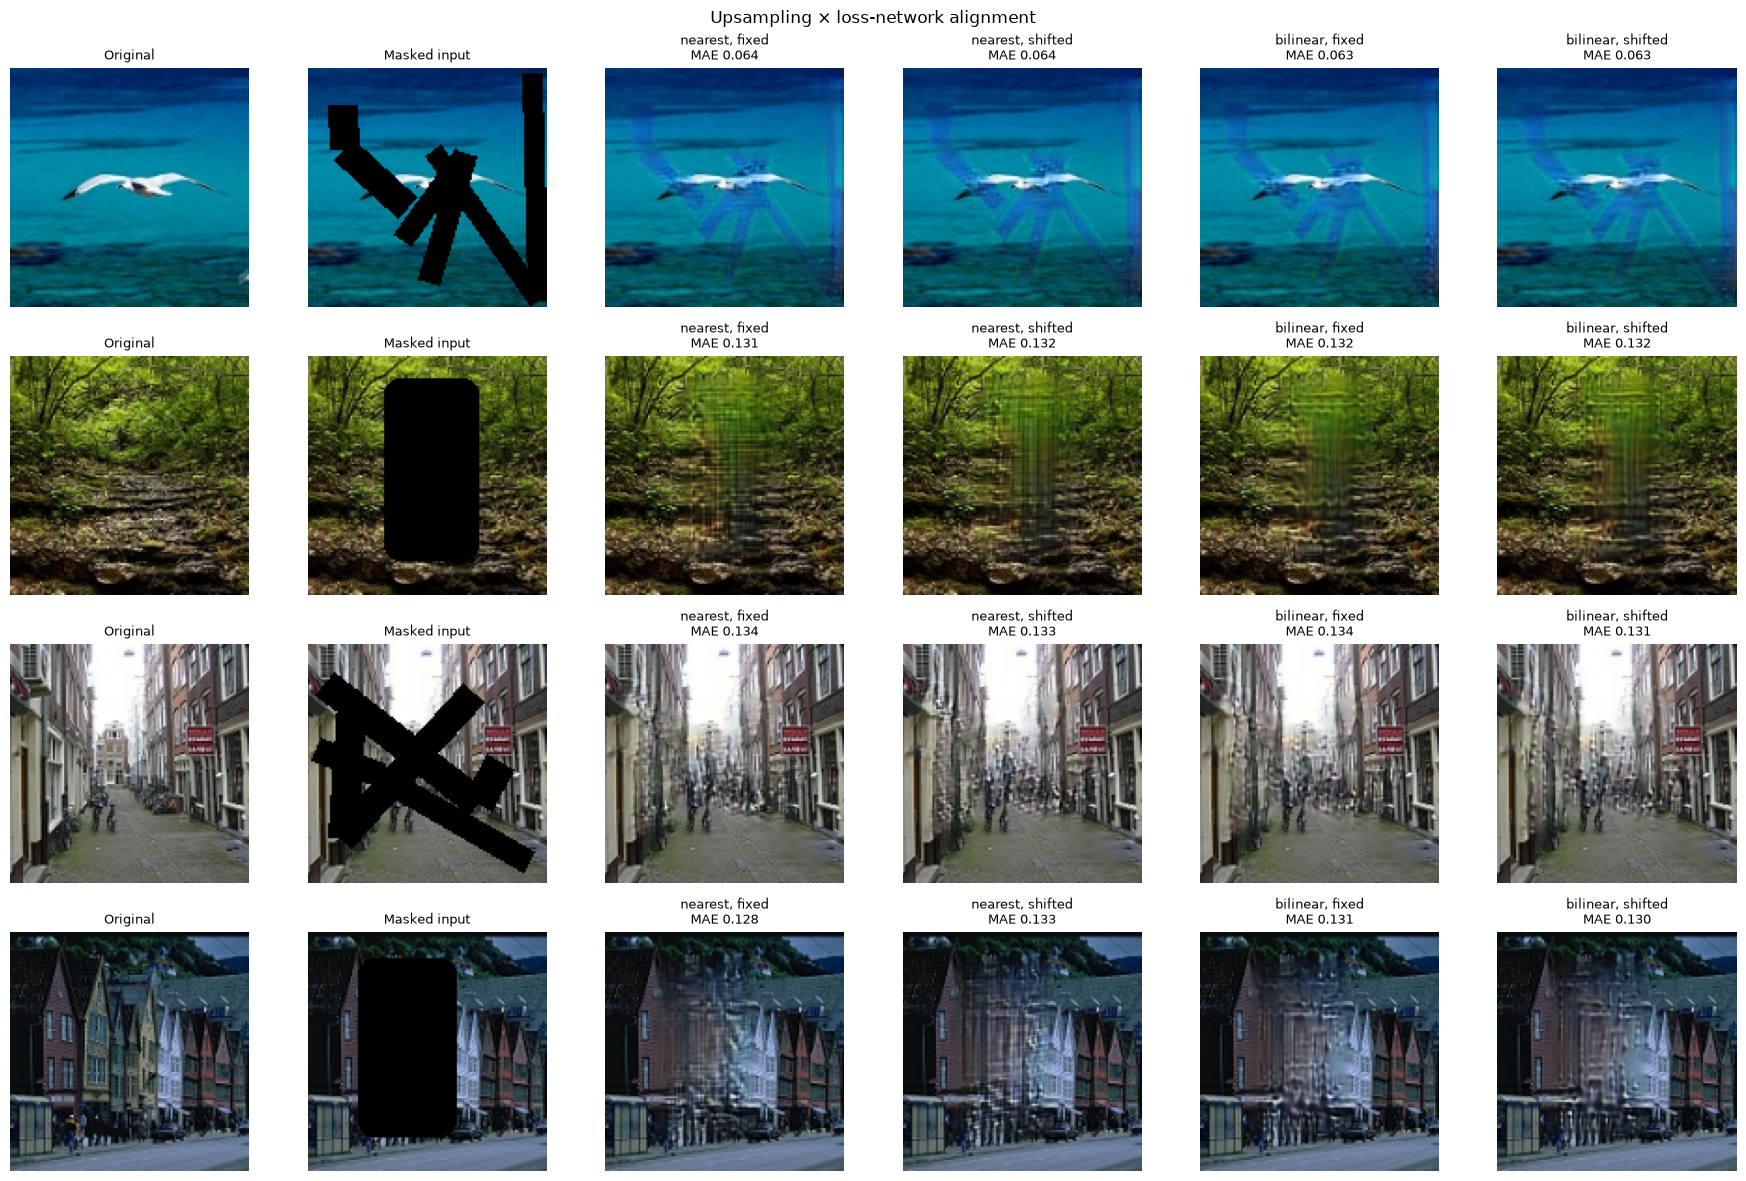

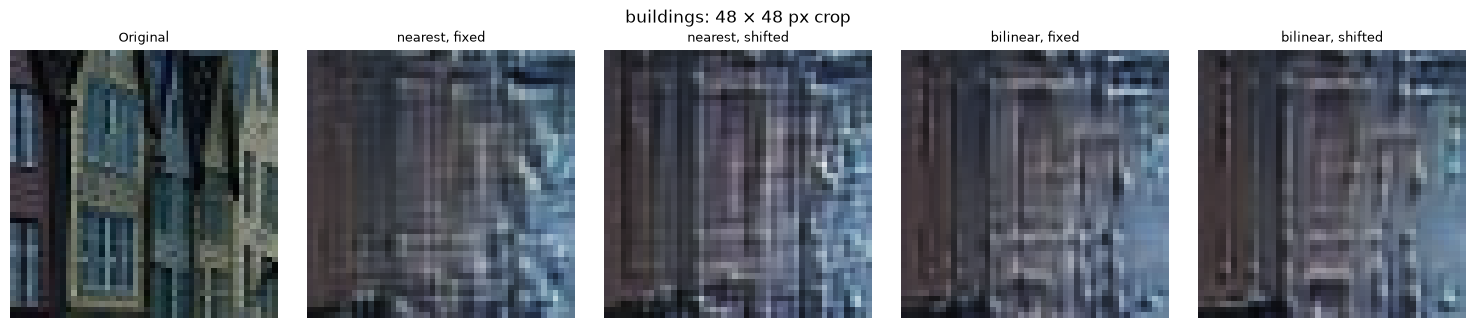

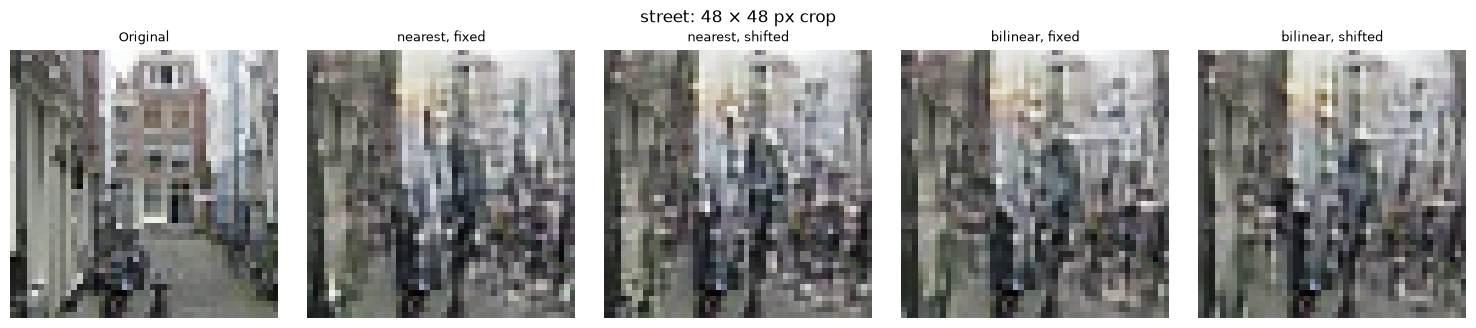

In [17]:
grid_results = {
    f"{upsampling}, {losses}": reconstructions[name]
    for name, (upsampling, losses, _) in GRID_CELLS.items()
}
show_comparison(validation, grid_results, examples, "Upsampling × loss-network alignment")

for category, index in zip(
    ["buildings", "street"], validation.example_indices(["buildings", "street"])
):
    show_zoom(validation, grid_results, index, title=f"{category}: 48 × 48 px crop")

### Stability of the Grid Measure

Each cell of the comparison is a single training run, measured once, after
its last update. Every run also keeps its checkpoint from 250 updates
earlier; the same measure there shows how much a component moves within one
run. Differences between cells that do not hold at both checkpoints are not
read as effects.

The coarse U-Net is listed too: every refiner starts from its fill, so its
grid is the level a refiner inherits.

In [18]:
from photo_retouch.training import restore_arm

STABILITY_RUNS = {
    # method: (checkpoint directory, log key, upsampling)
    "Low-chroma refiner": (MODEL_DIR / "refinement_followup", "low_chroma", "nearest"),
    **{
        name: (GRID_CHECKPOINT_DIR, key, upsampling)
        for name, (key, upsampling, _) in GRID_ARMS.items()
    },
}

stability_rows = []
for name, (directory, key, upsampling) in STABILITY_RUNS.items():
    arm = new_arm(
        key, refine_low_chroma, STYLE_WEIGHT, initial_refiner, initial_discriminator,
        upsampling=upsampling,
    )
    for path in tf.train.get_checkpoint_state(str(directory)).all_model_checkpoint_paths:
        update = restore_arm(arm, path)
        results = refine_images(
            arm.refiner, reconstructions[COARSE_NAME], validation.masks, refine_low_chroma
        )
        stability_rows.append({"method": name, "update": update, **grid_by_period(results)})
grid_stability = pd.DataFrame(stability_rows).set_index(["method", "update"])

# Each run's last checkpoint is the model evaluated above.
last = grid_stability.groupby(level="method", sort=False).tail(1).droplevel("update")
gap = (last - grid_source_table.loc[last.index, last.columns]).abs().max().max()
assert gap < TOLERANCE, gap
save_or_check(grid_stability, GRID_RECORD_DIR / "grid_stability.csv")

grid_reference = pd.DataFrame([
    pd.Series(grid_by_period(reconstructions[COARSE_NAME]), name="Coarse U-Net (refiner input)"),
    true_grid,
])
with pd.option_context("display.width", 250, "display.max_columns", 20):
    display(grid_stability.round(4))
    display(grid_reference.round(4))

grid 2 px (h)  grid 2 px (v)  grid 4 px (h)  grid 4 px (v)
method                         update                                                            
Low-chroma refiner             2750           0.0168         0.0392         0.0110         0.0187
                               3000           0.0277         0.0324         0.0107         0.0099
Low-chroma, bilinear           2750           0.0000         0.0217         0.0026         0.0006
                               3000           0.0162         0.0054         0.0017         0.0007
Low-chroma, shifted losses     2750           0.0822         0.0039         0.0030         0.0007
                               3000           0.0951         0.0116         0.0070         0.0001
Low-chroma, bilinear + shifted 2750           0.0423         0.0718         0.0044         0.0027
                               3000           0.0422         0.0660         0.0056         0.0036

,grid 2 px (h),grid 2 px (v),grid 4 px (h),grid 4 px (v)
Coarse U-Net (refiner input),0.0737,0.0648,0.0060,0.0099
True image,0.0004,0.0003,0.0046,0.0048


### Grid-Source Results

**The bilinear arm meets the criterion and is the new best candidate, by a
narrow margin. The grid has a different source for each period, and no
single prediction holds.**

*Revised by the second-seed replicate below: the bilinear candidate and the
4-px finding do not hold up.*

- **Movement within a run.** Between the last two checkpoints of one run, a
  component moves by up to 0.016 (bilinear, 2 px: 0.000 to 0.016
  horizontally, 0.022 to 0.005 vertically). Only differences that hold at
  both checkpoints are read below.
- **4 px: added by the refiner, and only with both nearest-neighbour
  upsampling and fixed loss networks.** The coarse fill has 0.006
  horizontally; the low-chroma refiner raises it to 0.011 at both
  checkpoints (vertically 0.010–0.019, against 0.010 in the fill). Each of
  the three changes brings both directions to 0.0001–0.007, near the true
  images' 0.005. Removing either factor is enough, so the 4-px grid needs
  both. This is consistent with a pattern that the loss networks favour at
  their fixed positions and that the 4 × 4 blocks of the first upsampling
  stage make easy to produce there.
- **2 px: inherited from the coarse U-Net, and reduced only with fixed loss
  networks.** The coarse fill already has 0.074 horizontally and 0.065
  vertically; the coarse U-Net also upsamples three times by nearest
  neighbour. The low-chroma refiner lowers this to 0.017–0.039, and bilinear
  upsampling with fixed losses to 0.000–0.022. With shifted losses, one
  direction stays at or above the fill's level at both checkpoints: 0.082–0.095
  horizontally for the shifted arm, 0.066–0.072 vertically for bilinear +
  shifted. The aligned loss networks do not create the 2-px grid; they help
  the refiner cancel the one in its input.
- **Visually,** shifted losses turn the small blocks into vertical streaks
  (nearest) or a lattice of thin lines (bilinear), in the facade crop and the
  forest fill. Bilinear upsampling with fixed losses gives the smoothest
  fill, with fainter vertical streaks.

**Criterion.** Bilinear upsampling lowers all four components, compared with
the low-chroma refiner at the same checkpoint, at both checkpoints. Its
perceptual interval is [−0.00003, +0.0099]: not entirely above zero, but only
just. On every other measure it is slightly worse: perceptual distance is
better in only 45% of images, masked MAE rises by 0.0003 (95% CI [+0.0001,
+0.0007]), and KID × 1000 rises from 0.07 to 0.53, a tie by the subset
standard deviation (about 2) but lower in only 7% of subsets. The shifted
and bilinear + shifted arms fail on the 2-px components.

**Next.** The 2-px grid that remains enters with the coarse fill, which the
refiner only partly cancels. A coarse U-Net with bilinear upsampling would
test that directly. Each cell here is a single run; a second seed would
show how much runs differ.

## Experiment: Replicate with a Second Seed

**Question.** Does the bilinear refiner's win hold up with a second seed, or
is it within the variation between training runs?

Every comparison so far trained each variant once, from one initialization
and one batch sequence. The paired intervals cover the choice of validation
images, not the randomness of training. Two runs of the same variant could
differ as much as two variants do. Within one run, grid components moved by
up to 0.016 over 250 updates. The bilinear arm met the criterion with a
perceptual interval whose lower end was −0.00003.

**Design.** Train the low-chroma refiner (nearest-neighbour upsampling) and
the bilinear refiner again, with new seeds for the initialization (2046),
the image order (2044), and the masks (2045). Everything else is unchanged:
losses, weights, 3,000 updates, and one starting point and batch sequence
shared by the two arms.

**What it measures.**

- The same comparison under a second seed: does bilinear again meet the
  criterion against the low-chroma refiner?
- The difference between two runs of the same variant, with the same
  paired measures. This is the variation that single-seed comparisons
  cannot see.

**Criterion** (fixed before training). The bilinear refiner stays the best
candidate only if, with the second seed, it again meets the criterion
against the low-chroma refiner of that seed: lower 2- and 4-px components in
both directions, and a paired 95% interval for perceptual distance that does
not lie entirely above zero. Otherwise its first result is read as within
the variation between runs, and the low-chroma refiner remains the
reference.

In [19]:
REPLICATE_SEEDS = {"order_seed": 2044, "mask_seed": 2045, "init_seed": 2046}
REPLICATE_STEPS = 3000
REPLICATE_ARMS = {
    # name: (log key, upsampling)
    "Low-chroma refiner, seed 2": ("low_chroma_seed2", "nearest"),
    "Low-chroma, bilinear, seed 2": ("bilinear_seed2", "bilinear"),
}
REPLICATE_RECORD_DIR = validation.record_dir / "refinement_replicate"
REPLICATE_CHECKPOINT_DIR = MODEL_DIR / "refinement_replicate"
REPLICATE_MODEL_DIR = MODEL_DIR

replicate_batches = TrainingBatches(
    order_seed=REPLICATE_SEEDS["order_seed"], mask_seed=REPLICATE_SEEDS["mask_seed"]
)
keras.utils.set_random_seed(REPLICATE_SEEDS["init_seed"])
replicate_initial_refiner = build_refiner("replicate_initial_refiner")
replicate_initial_discriminator = build_patch_discriminator()

replicate_arms = {
    name: new_arm(
        key, refine_low_chroma, STYLE_WEIGHT,
        replicate_initial_refiner, replicate_initial_discriminator, upsampling=upsampling,
    )
    for name, (key, upsampling) in REPLICATE_ARMS.items()
}


def largest_gap(a, b):
    return max(float(tf.reduce_max(tf.abs(x - y))) for x, y in zip(a, b))


# New starting weights and a new batch sequence ...
weight_gap = largest_gap(
    initial_refiner.get_weights() + initial_discriminator.get_weights(),
    replicate_initial_refiner.get_weights() + replicate_initial_discriminator.get_weights(),
)
probe_images, probe_masks = replicate_batches(0)
batch_gap = largest_gap(batches(0), (probe_images, probe_masks))
assert weight_gap > 0 and batch_gap > 0, (weight_gap, batch_gap)

# ... but again the identity at the start.
probe_coarse = coarse_composite(probe_images, probe_masks)
for name, arm in replicate_arms.items():
    gap = float(tf.reduce_max(tf.abs(
        refine_low_chroma(arm.refiner, probe_coarse, probe_masks) - probe_coarse
    )))
    assert gap < 2e-3, (name, gap)
    upsampling = arm.refiner.get_layer("up64").interpolation
    print(f"{name:<30} upsampling: {upsampling}")
print(f"Seeds: {REPLICATE_SEEDS}")

Low-chroma refiner, seed 2     upsampling: nearest
Low-chroma, bilinear, seed 2   upsampling: bilinear
Seeds: {'order_seed': 2044, 'mask_seed': 2045, 'init_seed': 2046}


### Train

In [20]:
replicate_arm_list = list(replicate_arms.values())
replicate_run = CheckpointedRun(
    replicate_arm_list,
    make_train_step(
        replicate_arm_list, coarse_composite, loss_features, PERCEPTUAL_WEIGHT, ADV_RATIO
    ),
    replicate_batches,
    REPLICATE_CHECKPOINT_DIR,
    REPLICATE_RECORD_DIR / "training_log.csv",
    settings={
        "perceptual_weight": PERCEPTUAL_WEIGHT,
        "style_weight": STYLE_WEIGHT,
        "adv_ratio": ADV_RATIO,
        "chroma_sigma": CHROMA_SIGMA,
        **REPLICATE_SEEDS,
        **{f"{key}_bilinear": float(upsampling == "bilinear")
           for key, upsampling in REPLICATE_ARMS.values()},
    },
)
replicate_run.run(REPLICATE_STEPS)

for arm in replicate_arm_list:
    arm.refiner.save(REPLICATE_MODEL_DIR / f"refiner_{arm.key}.keras")
print(f"Completed updates per variant: {replicate_run.completed}")

Steps 1–250 (1.59 s/step)
  low_chroma_seed2 L1: 0.0943 | Perc: 274.0 | Style: 722.9 | D: 1.857 | Adv weight: 0.272
  bilinear_seed2   L1: 0.0942 | Perc: 273.8 | Style: 725.5 | D: 1.835 | Adv weight: 0.22


Steps 251–500 (1.54 s/step)
  low_chroma_seed2 L1: 0.1022 | Perc: 278.6 | Style: 594.5 | D: 1.797 | Adv weight: 0.0572
  bilinear_seed2   L1: 0.1001 | Perc: 278.1 | Style: 633.2 | D: 1.758 | Adv weight: 0.051


Steps 501–750 (1.52 s/step)
  low_chroma_seed2 L1: 0.1020 | Perc: 273.7 | Style: 546.0 | D: 1.771 | Adv weight: 0.0558
  bilinear_seed2   L1: 0.1027 | Perc: 276.4 | Style: 565.2 | D: 1.792 | Adv weight: 0.0477


Steps 751–1000 (1.51 s/step)
  low_chroma_seed2 L1: 0.1010 | Perc: 271.8 | Style: 527.9 | D: 1.739 | Adv weight: 0.0498
  bilinear_seed2   L1: 0.1010 | Perc: 273.6 | Style: 553.4 | D: 1.756 | Adv weight: 0.0485


Steps 1001–1250 (1.52 s/step)
  low_chroma_seed2 L1: 0.1045 | Perc: 272.0 | Style: 468.9 | D: 1.837 | Adv weight: 0.0517
  bilinear_seed2   L1: 0.1024 | Perc: 272.9 | Style: 511.1 | D: 1.762 | Adv weight: 0.0467


Steps 1251–1500 (1.51 s/step)
  low_chroma_seed2 L1: 0.1047 | Perc: 271.1 | Style: 439.9 | D: 1.864 | Adv weight: 0.0459
  bilinear_seed2   L1: 0.1041 | Perc: 273.7 | Style: 458.6 | D: 1.826 | Adv weight: 0.0444


... (3 outputs left out)

Steps 2251–2500 (1.53 s/step)
  low_chroma_seed2 L1: 0.1049 | Perc: 266.9 | Style: 413.3 | D: 1.880 | Adv weight: 0.0469
  bilinear_seed2   L1: 0.1045 | Perc: 267.3 | Style: 417.9 | D: 1.857 | Adv weight: 0.0365


Steps 2501–2750 (1.52 s/step)
  low_chroma_seed2 L1: 0.1043 | Perc: 266.3 | Style: 412.2 | D: 1.883 | Adv weight: 0.0463
  bilinear_seed2   L1: 0.1039 | Perc: 266.5 | Style: 414.6 | D: 1.858 | Adv weight: 0.0345


Steps 2751–3000 (1.51 s/step)
  low_chroma_seed2 L1: 0.1051 | Perc: 266.8 | Style: 412.1 | D: 1.882 | Adv weight: 0.0456
  bilinear_seed2   L1: 0.1047 | Perc: 267.1 | Style: 413.9 | D: 1.869 | Adv weight: 0.0366


Completed updates per variant: 3000


### Evaluate

Both variants under both seeds. The paired comparisons are the criterion
(bilinear against low-chroma, seed 2), the same comparison under seed 1 for
reference, and each variant's second run against its first. The grid is
also measured at the second-to-last checkpoint of the new runs, as in the
stability check.

In [21]:
REPLICATE_RECORD_DIR.mkdir(parents=True, exist_ok=True)

for name, arm in replicate_arms.items():
    reconstructions[name] = refine_images(
        arm.refiner, reconstructions[COARSE_NAME], validation.masks, refine_low_chroma
    )
    evaluations[name] = evaluator.evaluate(reconstructions[name])

REPLICATE_CELLS = {
    # method: (upsampling, seed, log key)
    "Low-chroma refiner": ("nearest", 1, "low_chroma"),
    "Low-chroma, bilinear": ("bilinear", 1, "bilinear"),
    "Low-chroma refiner, seed 2": ("nearest", 2, "low_chroma_seed2"),
    "Low-chroma, bilinear, seed 2": ("bilinear", 2, "bilinear_seed2"),
}
replicate_logs = grid_logs.join(replicate_run.log_frame().set_index("step"))
replicate_last_window = replicate_logs[replicate_logs.index > REPLICATE_STEPS - 250]

replicate_rows = []
for name, (upsampling, seed, key) in REPLICATE_CELLS.items():
    summary = evaluations[name].summary()
    detail = evaluator.detail_summary(reconstructions[name])
    replicate_rows.append({
        "method": name,
        "upsampling": upsampling,
        "seed": seed,
        "masked_mae": summary["masked_mae"],
        "feature_distance": summary["feature_distance"],
        "kid_x1000": summary["kid_x1000"],
        "luma_detail_ratio": detail["luma_detail_ratio"],
        "chroma_detail_ratio": detail["chroma_detail_ratio"],
        **grid_by_period(reconstructions[name]),
        "train_gram_distance": replicate_last_window[f"{key}_style"].mean(),
        "train_l1": replicate_last_window[f"{key}_l1"].mean(),
    })
replicate_table = pd.DataFrame(replicate_rows).set_index("method")

REPLICATE_PAIRS = [
    ("Low-chroma, bilinear, seed 2", "Low-chroma refiner, seed 2"),
    ("Low-chroma, bilinear", "Low-chroma refiner"),
    ("Low-chroma refiner, seed 2", "Low-chroma refiner"),
    ("Low-chroma, bilinear, seed 2", "Low-chroma, bilinear"),
]
replicate_paired = pd.DataFrame([
    {"method": method, "baseline": baseline,
     **evaluator.paired(evaluations[method], evaluations[baseline])}
    for method, baseline in REPLICATE_PAIRS
]).set_index(["method", "baseline"])

replicate_stability_rows = []
for name, (key, upsampling) in REPLICATE_ARMS.items():
    arm = new_arm(
        key, refine_low_chroma, STYLE_WEIGHT,
        replicate_initial_refiner, replicate_initial_discriminator, upsampling=upsampling,
    )
    for path in tf.train.get_checkpoint_state(
        str(REPLICATE_CHECKPOINT_DIR)
    ).all_model_checkpoint_paths:
        update = restore_arm(arm, path)
        results = refine_images(
            arm.refiner, reconstructions[COARSE_NAME], validation.masks, refine_low_chroma
        )
        replicate_stability_rows.append(
            {"method": name, "update": update, **grid_by_period(results)}
        )
replicate_stability = pd.DataFrame(replicate_stability_rows).set_index(["method", "update"])
last = replicate_stability.groupby(level="method", sort=False).tail(1).droplevel("update")
gap = (last - replicate_table.loc[last.index, last.columns]).abs().max().max()
assert gap < TOLERANCE, gap

save_or_check(replicate_table, REPLICATE_RECORD_DIR / "replicate_summary.csv")
save_or_check(replicate_paired, REPLICATE_RECORD_DIR / "paired_comparisons.csv")
save_or_check(
    pd.DataFrame({
        name: evaluations[name].summary() for name in REPLICATE_ARMS
    }).T.rename_axis("method"),
    REPLICATE_RECORD_DIR / "metric_summary.csv",
)
save_or_check(pd.DataFrame([
    {"method": name, **row}
    for name in REPLICATE_ARMS
    for row in evaluator.grid_periodicity(reconstructions[name])
]).set_index(["method", "direction"]), REPLICATE_RECORD_DIR / "grid_periodicity.csv")
save_or_check(replicate_stability, REPLICATE_RECORD_DIR / "grid_stability.csv")

with pd.option_context("display.width", 250, "display.max_columns", 20):
    display(replicate_table.round(4))
    display(replicate_paired.round(4))
    display(pd.concat([
        grid_stability.loc[["Low-chroma refiner", "Low-chroma, bilinear"]],
        replicate_stability,
    ]).round(4))

,upsampling,seed,masked_mae,feature_distance,kid_x1000,luma_detail_ratio,chroma_detail_ratio,grid 2 px (h),grid 2 px (v),grid 4 px (h),grid 4 px (v),train_gram_distance,train_l1
method,,,,,,,,,,,,,
Low-chroma refiner,nearest,1,0.1059,0.7083,0.0677,0.8070,1.0888,0.0277,0.0324,0.0107,0.0099,406.5584,0.1052
"Low-chroma, bilinear",bilinear,1,0.1063,0.7132,0.5320,0.8137,1.0318,0.0162,0.0054,0.0017,0.0007,410.4526,0.1051
"Low-chroma refiner, seed 2",nearest,2,0.1020,0.7098,-0.0350,0.6210,0.8076,0.0008,0.0130,0.0009,0.0029,412.1004,0.1051
"Low-chroma, bilinear, seed 2",bilinear,2,0.1024,0.7158,0.3690,0.6555,0.8660,0.0228,0.0300,0.0052,0.0017,413.8680,0.1047


,,masked_mae Δ,masked_mae 95% CI,masked_mae images better,feature_distance Δ,feature_distance 95% CI,feature_distance images better,KID×1000 Δ,KID subsets lower
method,baseline,,,,,,,,
"Low-chroma, bilinear, seed 2","Low-chroma refiner, seed 2",0.0005,"[+0.0002, +0.0007]",48%,0.0060,"[+0.0024, +0.0096]",42%,0.4040,8%
"Low-chroma, bilinear",Low-chroma refiner,0.0003,"[+0.0001, +0.0007]",45%,0.0049,"[-0.0000, +0.0099]",45%,0.4644,7%
"Low-chroma refiner, seed 2",Low-chroma refiner,-0.0040,"[-0.0044, -0.0036]",86%,0.0015,"[-0.0042, +0.0072]",50%,-0.1027,69%
"Low-chroma, bilinear, seed 2","Low-chroma, bilinear",-0.0038,"[-0.0043, -0.0034]",86%,0.0026,"[-0.0031, +0.0081]",50%,-0.1631,72%


grid 2 px (h)  grid 2 px (v)  grid 4 px (h)  grid 4 px (v)
method                       update                                                            
Low-chroma refiner           2750           0.0168         0.0392         0.0110         0.0187
                             3000           0.0277         0.0324         0.0107         0.0099
Low-chroma, bilinear         2750           0.0000         0.0217         0.0026         0.0006
                             3000           0.0162         0.0054         0.0017         0.0007
Low-chroma refiner, seed 2   2750           0.0052         0.0123         0.0027         0.0030
                             3000           0.0008         0.0130         0.0009         0.0029
Low-chroma, bilinear, seed 2 2750           0.0303         0.0320         0.0038         0.0035
                             3000           0.0228         0.0300         0.0052         0.0017

### Visual Check

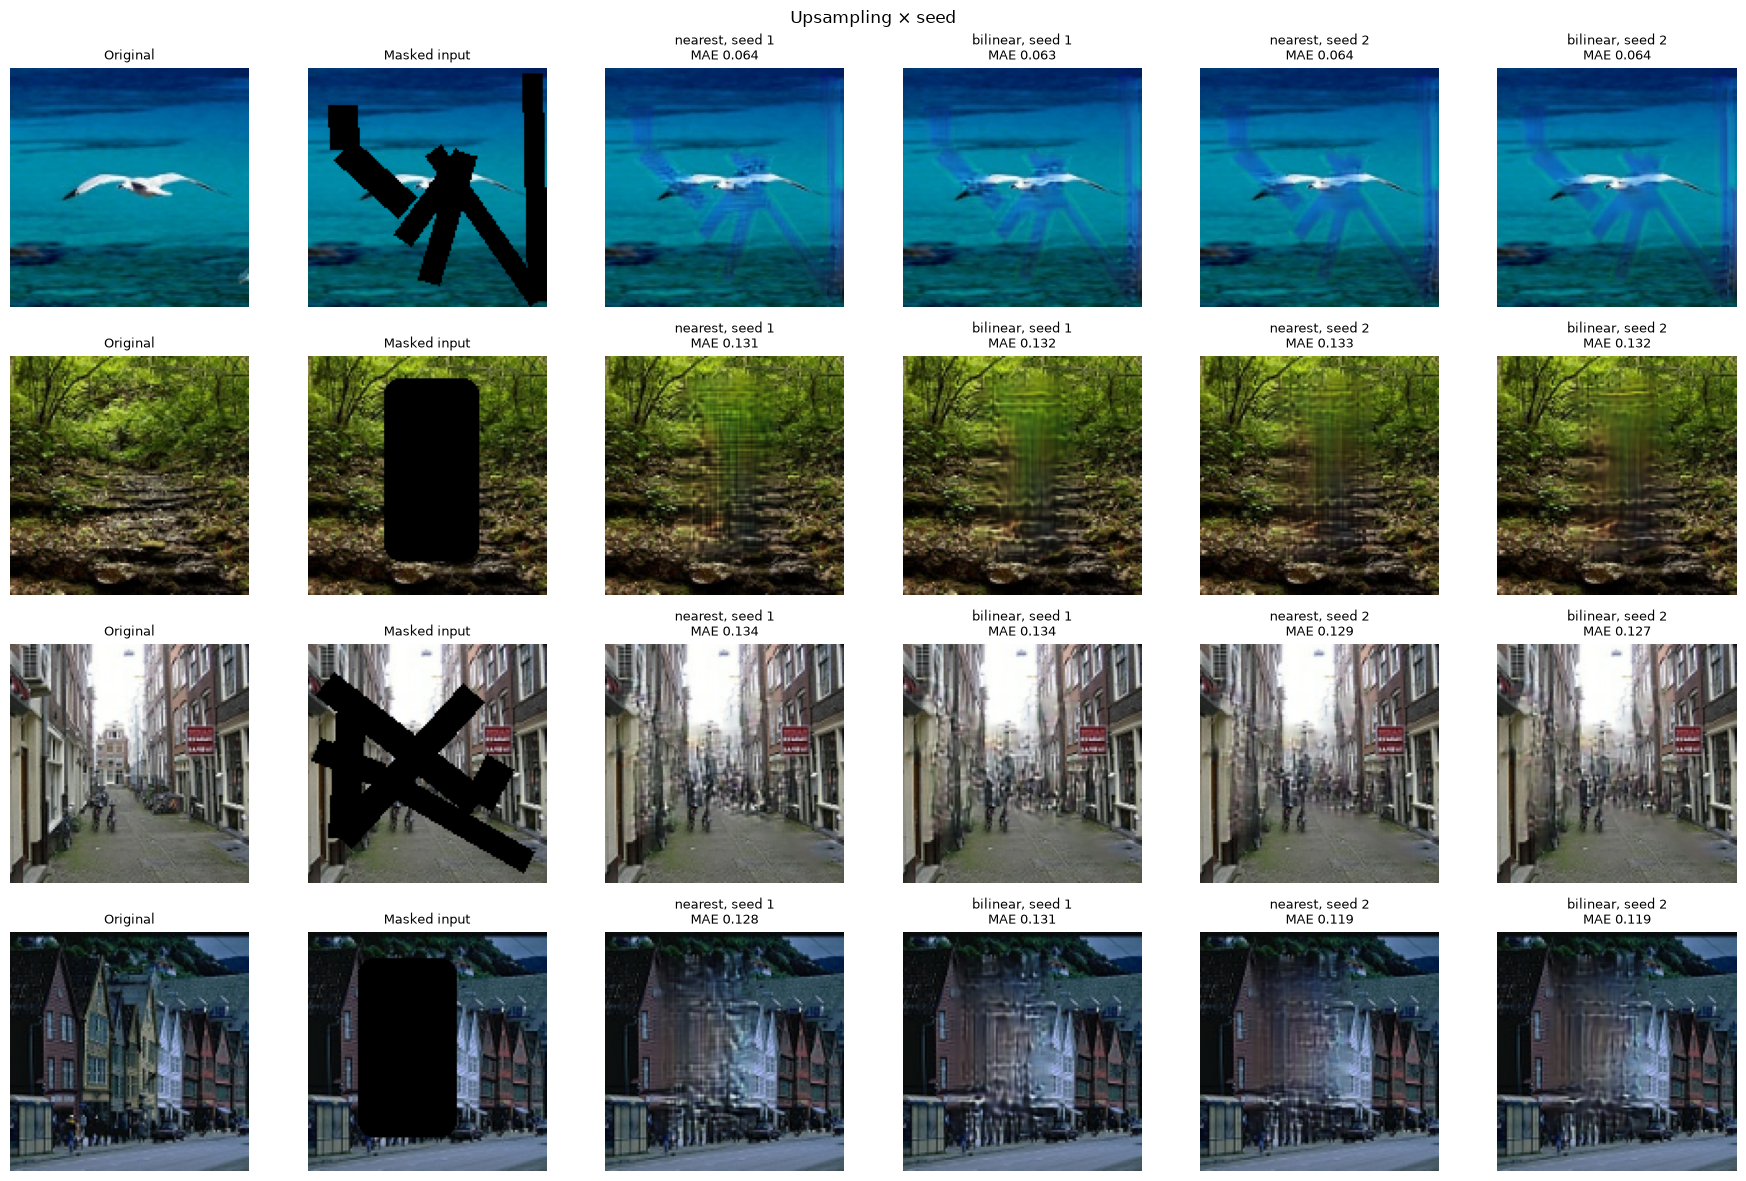

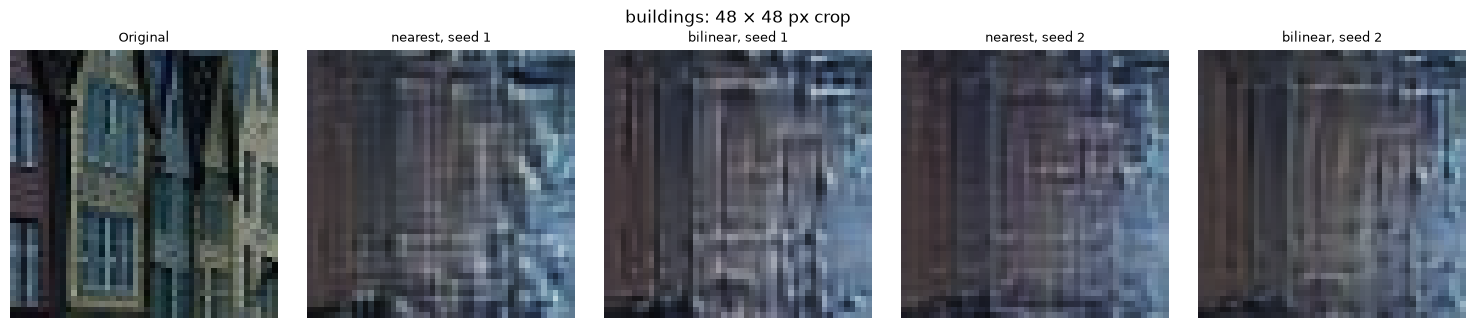

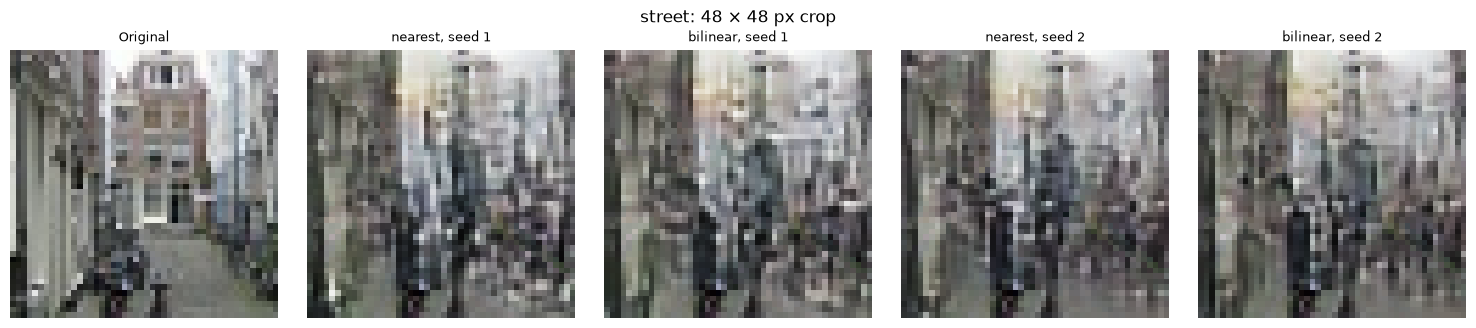

In [22]:
replicate_results = {
    f"{upsampling}, seed {seed}": reconstructions[name]
    for name, (upsampling, seed, _) in REPLICATE_CELLS.items()
}
show_comparison(validation, replicate_results, examples, "Upsampling × seed")

for category, index in zip(
    ["buildings", "street"], validation.example_indices(["buildings", "street"])
):
    show_zoom(validation, replicate_results, index, title=f"{category}: 48 × 48 px crop")

### Replicate Results

**The criterion is not met. The bilinear refiner's first result is within
the variation between runs, and the low-chroma refiner remains the
reference.**

- **Criterion.** With seed 2, bilinear upsampling has higher 2-px components
  in both directions (0.023 and 0.030, against 0.001 and 0.013) and a higher
  horizontal 4-px component (0.005 against 0.001) than the low-chroma refiner
  of the same seed, at both checkpoints. Its perceptual interval,
  [+0.0024, +0.0096], lies entirely above zero.
- **What replicates: bilinear upsampling is slightly worse on the image
  measures.** Against the low-chroma refiner of the same seed, perceptual
  distance rises by 0.0049 and 0.0060 (seeds 1 and 2), masked MAE by 0.0003
  and 0.0005, and KID × 1000 by 0.46 and 0.40 (lower in 7% and 8% of
  subsets).
- **What does not: the grid.** With seed 1, bilinear upsampling lowered all
  four components; with seed 2, it raises three of them. The
  nearest-neighbour refiner alone has 4-px components of 0.010–0.019 with
  seed 1 and 0.001–0.003 with seed 2, below the true images' 0.005.
- **Two runs of the same variant.** With seed 2, both variants have a lower
  masked MAE (−0.0040, 95% CI [−0.0044, −0.0036], and −0.0038,
  [−0.0043, −0.0034]) and less fine detail (luma detail ratios 0.62 and
  0.66, against 0.81; chroma 0.81 and 0.87, against 1.09 and 1.03).
  Perceptual distance does not change (+0.0015, [−0.0042, +0.0072]; +0.0026,
  [−0.0031, +0.0081]). In the crops, the second runs are smoother and less
  contrasted. The masked-MAE intervals exclude zero although the variant is
  the same: the paired intervals measure the choice of images, not the
  training run.

**Earlier conclusions, revised.**

- **Grid source.** The 4-px finding does not hold: the variant it singled
  out, nearest-neighbour upsampling with fixed losses, has almost no 4-px
  grid with seed 2. What remains is the effect of shifted losses on the
  2-px components: 0.082–0.095 horizontally and 0.066–0.072 vertically,
  against at most 0.030 and 0.039 without shifting, over both seeds and both
  checkpoints. Each shifted variant was trained only once.
- **Style weight.** Its perceptual effects (+0.050 and +0.094) are far larger
  than the difference between two runs, and its masked-MAE effects (+0.0085
  and +0.0104) two to three times larger. Those conclusions stand.
- **Single runs.** A difference between two single runs supports a design
  only if it is clearly larger than the difference between seeds: about
  0.004 in masked MAE. For the grid components, the two seeds of one design
  differ by nearly the whole range observed without shifted losses.

**Next.** The seed-2 low-chroma refiner has less grid and a lower masked
MAE than the first run, at the cost of less fine detail. Choosing it would
be a selection between runs on the validation set, so its final figures
would have to come from the test set.